# Datadriven analys av handläggningstid i ärendehantering

Projektet analyserar handläggningstid i ett ärendehanteringssystem med hjälp av explorativ dataanalys och maskininlärning.  
Syftet är att identifiera faktorer kopplade till handläggningstid och processens effektivitet samt undersöka om handläggningstid kan predikteras med hjälp av processrelaterade variabler.

---

## Import och datainläsning

In [1]:
# Databehandling och visualisering
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Modelltolkning
import shap

# Modellering och utvärdering
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid")

In [2]:
# Läs in datasetet (en rad per händelse)
file_path = "../data_input/incident_event_log.csv"
df = pd.read_csv(file_path)
df.head()

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,...,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


Datasetet innehåller loggdata från ett ärendehanteringssystem där varje rad representerar en händelse i processen.  
Variablerna beskriver bland annat statusförändringar, prioritet, tilldelning och tidsstämplar för olika steg i handläggningen.

In [3]:
# Antal rader och kolumner
df.shape

(141712, 36)

In [4]:
# Kolumnnamn
df.columns

Index(['number', 'incident_state', 'active', 'reassignment_count',
       'reopen_count', 'sys_mod_count', 'made_sla', 'caller_id', 'opened_by',
       'opened_at', 'sys_created_by', 'sys_created_at', 'sys_updated_by',
       'sys_updated_at', 'contact_type', 'location', 'category', 'subcategory',
       'u_symptom', 'cmdb_ci', 'impact', 'urgency', 'priority',
       'assignment_group', 'assigned_to', 'knowledge',
       'u_priority_confirmation', 'notify', 'problem_id', 'rfc', 'vendor',
       'caused_by', 'closed_code', 'resolved_by', 'resolved_at', 'closed_at'],
      dtype='object')

In [5]:
# Antal unika ärenden (flera rader per ärende)
print("Antal unika ärenden:", df["number"].nunique())

Antal unika ärenden: 24918


En första genomgång visar att datasetet innehåller flera observationer per ärende.   
Datan representerar därmed ett processflöde över tid snarare än en enskild registrering per ärende, vilket behöver beaktas i den fortsatta analysen.

---

## Dataförståelse


In [6]:
# Undersök datatyper och antal observationer
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   number                   141712 non-null  object
 1   incident_state           141712 non-null  object
 2   active                   141712 non-null  bool  
 3   reassignment_count       141712 non-null  int64 
 4   reopen_count             141712 non-null  int64 
 5   sys_mod_count            141712 non-null  int64 
 6   made_sla                 141712 non-null  bool  
 7   caller_id                141712 non-null  object
 8   opened_by                141712 non-null  object
 9   opened_at                141712 non-null  object
 10  sys_created_by           141712 non-null  object
 11  sys_created_at           141712 non-null  object
 12  sys_updated_by           141712 non-null  object
 13  sys_updated_at           141712 non-null  object
 14  contact_type        

Flera tidsrelaterade variabler är initialt lagrade som text och behöver därför konverteras till datetime-format innan vidare analys kan genomföras.

In [7]:
# Kontrollera saknade värden i rådata
df.isna().sum()

number                     0
incident_state             0
active                     0
reassignment_count         0
reopen_count               0
sys_mod_count              0
made_sla                   0
caller_id                  0
opened_by                  0
opened_at                  0
sys_created_by             0
sys_created_at             0
sys_updated_by             0
sys_updated_at             0
contact_type               0
location                   0
category                   0
subcategory                0
u_symptom                  0
cmdb_ci                    0
impact                     0
urgency                    0
priority                   0
assignment_group           0
assigned_to                0
knowledge                  0
u_priority_confirmation    0
notify                     0
problem_id                 0
rfc                        0
vendor                     0
caused_by                  0
closed_code                0
resolved_by                0
resolved_at   

Inga formella saknade värden identifierades i rådata.  
Saknade uppgifter är dock markerade med `?`, som pandas tolkar som vanlig text.

---

## Datarensning & Transformering


In [8]:
# Standardisera kolumnnamn
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

# Ersätt frågetecken med saknade värden
df = df.replace("?", np.nan)

# Konvertera tidskolumner till datetime-format
date_columns = [
    "opened_at",
    "sys_created_at",
    "sys_updated_at",
    "resolved_at",
    "closed_at",
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce", dayfirst=True)

Kolumnnamnen har standardiserats, frågetecken har ersatts med saknade värden och tidskolumnerna har konverterats till datetime-format.

In [9]:
# Kontrollera saknade värden efter rensning
df.isna().sum()

number                          0
incident_state                  0
active                          0
reassignment_count              0
reopen_count                    0
sys_mod_count                   0
made_sla                        0
caller_id                      29
opened_by                    4835
opened_at                       0
sys_created_by              53076
sys_created_at              53076
sys_updated_by                  0
sys_updated_at                  0
contact_type                    0
location                       76
category                       78
subcategory                   111
u_symptom                   32964
cmdb_ci                    141267
impact                          0
urgency                         0
priority                        0
assignment_group            14213
assigned_to                 27496
knowledge                       0
u_priority_confirmation         0
notify                          0
problem_id                 139417
rfc           

Efter rensningen identifieras saknade värden i flera variabler.   

---

## Aggregering till ärendenivå

In [10]:
# Sortera händelser kronologiskt inom varje ärende
df = df.sort_values(["number", "sys_updated_at"])

# Aggregera flera händelser till en rad per ärende
df_grouped = (
    df.groupby("number")
    .agg(
        {
            "opened_at": "min",
            "resolved_at": "max",
            "reassignment_count": "max",
            "reopen_count": "max",
            "sys_mod_count": "max",
            # priority: "first" eftersom initial prioritet är mest relevant
            "priority": "first",
            # assignment_group, made_sla: "last" eftersom sista värdet gäller vid avslut
            "assignment_group": "last",
            "made_sla": "last",
            # category, subcategory: "first" eftersom ärendetypen sätts vid öppning
            "category": "first",
            "subcategory": "first",
            # contact_type: "first" eftersom kontaktvägen är känd vid start
            "contact_type": "first",
            # impact, urgency: "first" eftersom de sätts initialt och bestämmer priority
            "impact": "first",
            "urgency": "first",
        }
    )
    .reset_index()
)

Eftersom datasetet innehåller flera observationer per ärende aggregeras datan till en rad per ärende.  
Detta gör det möjligt att analysera handläggningstid och andra egenskaper på ärendenivå.  

In [11]:
# Kontrollera aggregerad data
df_grouped.head()

,number,opened_at,resolved_at,reassignment_count,reopen_count,sys_mod_count,priority,assignment_group,made_sla,category,subcategory,contact_type,impact,urgency
0,INC0000045,2016-02-29 01:16:00,2016-02-29 11:29:00,0,0,4,3 - Moderate,Group 56,True,Category 55,Subcategory 170,Phone,2 - Medium,2 - Medium
1,INC0000047,2016-02-29 04:40:00,2016-03-01 09:52:00,1,0,8,3 - Moderate,Group 24,True,Category 40,Subcategory 215,Phone,2 - Medium,2 - Medium
2,INC0000057,2016-02-29 06:10:00,2016-03-01 02:55:00,0,0,6,3 - Moderate,Group 70,True,Category 20,Subcategory 125,Phone,2 - Medium,2 - Medium
3,INC0000060,2016-02-29 06:38:00,2016-03-02 12:06:00,0,0,3,3 - Moderate,Group 25,True,Category 9,Subcategory 97,Phone,2 - Medium,2 - Medium
4,INC0000062,2016-02-29 06:58:00,2016-02-29 15:51:00,1,0,7,3 - Moderate,Group 23,False,Category 53,Subcategory 168,Phone,2 - Medium,2 - Medium


In [12]:
# Antal ärenden (rader) och kolumner efter aggregering
df_grouped.shape

(24918, 14)

In [13]:
# Kontrollera saknade resolved_at efter aggregering
print("Saknade resolved_at efter aggregering:", df_grouped["resolved_at"].isna().sum())

Saknade resolved_at efter aggregering: 1556


In [14]:
# Kontrollera att impact och urgency tillsammans entydigt bestämmer priority
print(df_grouped[["priority", "impact", "urgency"]].drop_duplicates().shape)
print(df_grouped.groupby(["impact", "urgency"])["priority"].unique())

(7, 3)
impact      urgency   
1 - High    1 - High      [1 - Critical]
            2 - Medium        [2 - High]
2 - Medium  1 - High          [2 - High]
            2 - Medium    [3 - Moderate]
            3 - Low            [4 - Low]
3 - Low     2 - Medium         [4 - Low]
            3 - Low            [4 - Low]
Name: priority, dtype: object


Resultatet visar att varje observerad kombination av `impact` och `urgency` motsvarar ett enda prioritetsvärde.   
Eftersom variablerna innehåller överlappande information används `priority` i modelleringen, medan `impact` och `urgency` exkluderas.

---

## Feature Engineering

In [15]:
# Skapa handläggningstid i timmar
df_grouped["handling_time_hours"] = (
    (df_grouped["resolved_at"] - df_grouped["opened_at"])
    .dt.total_seconds() / 3600
)

# Kontrollera orsaken innan ärenden exkluderas: saknat resolved_at eller negativ tid
n_missing = df_grouped["handling_time_hours"].isna().sum()
n_truly_negative = (df_grouped["handling_time_hours"] < 0).sum()
print(f"Saknade (NaT) handläggningstider: {n_missing}")
print(f"Faktiskt negativa handläggningstider: {n_truly_negative}")
print(f"Summa: {n_missing + n_truly_negative}")

# Exkludera ärenden utan handläggningstid eller med negativ tid
n_before = df_grouped.shape[0]
df_grouped = df_grouped[df_grouped["handling_time_hours"] >= 0].copy()
n_excluded = n_before - df_grouped.shape[0]
print(
    f"Exkluderade {n_excluded} ärenden ({n_excluded / n_before * 100:.1f}%) "
    "pga saknad eller negativ handläggningstid"
)

# Handläggningstid i dagar
df_grouped["handling_time_days"] = df_grouped["handling_time_hours"] / 24

Saknade (NaT) handläggningstider: 1556
Faktiskt negativa handläggningstider: 0
Summa: 1556
Exkluderade 1556 ärenden (6.2%) pga saknad eller negativ handläggningstid


Handläggningstiden har beräknats som skillnaden mellan `resolved_at` och `opened_at`.   
Ärenden med saknad eller negativ handläggningstid har exkluderats från den fortsatta analysen.

In [16]:
# Indikator för återöppnade ärenden
df_grouped["reopened_case"] = (
    df_grouped["reopen_count"] > 0
).astype(int)

# Indikator för hög aktivitetsnivå: fler uppdateringar än medianen
activity_threshold = df_grouped["sys_mod_count"].median()

df_grouped["high_activity_case"] = (
    df_grouped["sys_mod_count"] > activity_threshold
).astype(int)

Två nya variabler har skapats: `reopened_case`, som anger om ett ärende har återöppnats, och `high_activity_case`, som identifierar ärenden med fler uppdateringar än medianen.

In [17]:
# Kontrollera skapade variabler
df_grouped[
    [
        "number",
        "handling_time_days",
        "reopened_case",
        "high_activity_case",
    ]
].head()

,number,handling_time_days,reopened_case,high_activity_case
0,INC0000045,0.425694,0,0
1,INC0000047,1.216667,0,1
2,INC0000057,0.864583,0,1
3,INC0000060,2.227778,0,0
4,INC0000062,0.370139,0,1


---

## KPI-sammanfattning


In [18]:
# KPI-sammanfattning för ärendehanteringen
handling_days = df_grouped["handling_time_days"]

# SLA-uppfyllelse: andel ärenden där SLA-målet uppfylldes
sla_met = (df_grouped["made_sla"].astype(str).str.lower() == "true").mean() * 100

# Långdragna ärenden: handläggningstid över 75:e percentilen
long_cases = (handling_days > handling_days.quantile(0.75)).mean() * 100

kpi_summary = pd.DataFrame(
    {
        "KPI": [
            "Antal ärenden",
            "Genomsnittlig handläggningstid (dagar)",
            "Median handläggningstid (dagar)",
            "SLA-uppfyllelse (%)",
            "Andel återöppnade ärenden (%)",
            "Genomsnittligt antal omfördelningar",
            "Andel långdragna ärenden (%)",
        ],
        "Värde": [
            df_grouped["number"].nunique(),
            round(handling_days.mean(), 2),
            round(handling_days.median(), 2),
            round(sla_met, 1),
            round(df_grouped["reopened_case"].mean() * 100, 1),
            round(df_grouped["reassignment_count"].mean(), 2),
            round(long_cases, 1),
        ],
    }
)

kpi_summary

,KPI,Värde
0,Antal ärenden,23362.00
1,Genomsnittlig handläggningstid (dagar),7.42
2,Median handläggningstid (dagar),0.92
3,SLA-uppfyllelse (%),61.80
4,Andel återöppnade ärenden (%),1.20
5,Genomsnittligt antal omfördelningar,1.00
6,Andel långdragna ärenden (%),25.00


KPI-sammanställningen visar att handläggningstiden är tydligt snedfördelad.   
Medianen på 0,92 dagar är betydligt lägre än genomsnittet på 7,42 dagar, vilket tyder på att ett mindre antal ärenden med långa handläggningstider höjer genomsnittet.

Medianen understiger ett dygn, vilket innebär att minst hälften av ärendena har en handläggningstid på högst cirka ett dygn.   
SLA-uppfyllelsen är 61,8 %, vilket innebär att 38,2 % av ärendena inte uppfyller SLA enligt den registrerade variabeln.


---

## Explorativ Dataanalys (EDA)


In [19]:
# Sammanfattande statistik för handläggningstid
df_grouped["handling_time_days"].describe()

count    23362.000000
mean         7.423816
std         22.199491
min          0.000000
25%          0.017361
50%          0.920833
75%          6.186632
max        336.256944
Name: handling_time_days, dtype: float64

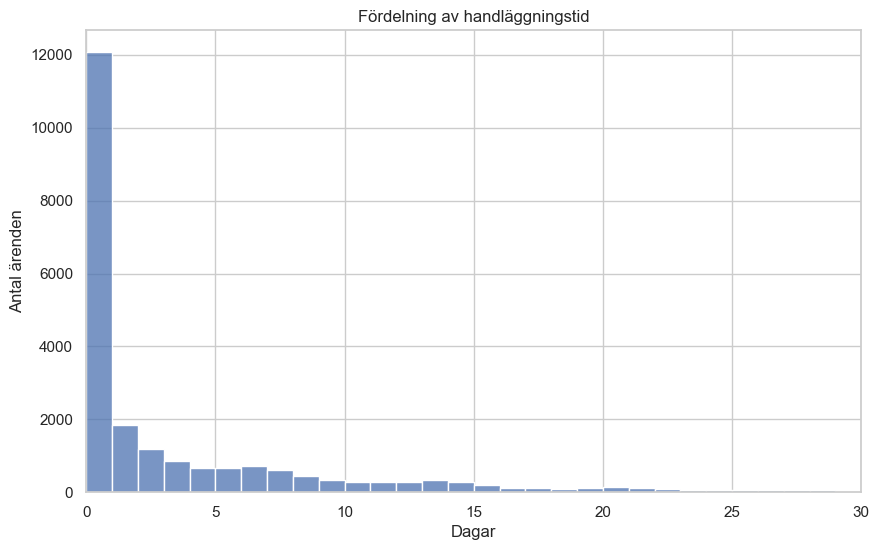

In [20]:
# Fördelning av handläggningstid (visar 0-30 dagar)
plt.figure(figsize=(10, 6))
sns.histplot(
    df_grouped["handling_time_days"],
    bins=30,
    binrange=(0, 30),
)

plt.xlim(0, 30)
plt.title("Fördelning av handläggningstid")
plt.xlabel("Dagar")
plt.ylabel("Antal ärenden")
plt.savefig("../images/eda_fordelning.png", dpi=150, bbox_inches="tight")
plt.show()

Fördelningen av handläggningstid är tydligt snedfördelad.   
Majoriteten av ärendena avslutas inom några få dagar, medan ett mindre antal ärenden har betydligt längre handläggningstider.   
X-axeln har begränsats till 30 dagar för att göra fördelningen lättare att urskilja.

In [21]:
# Handläggningstid per prioritet, sorterad på medelvärde
priority_stats = (
    df_grouped.groupby("priority")["handling_time_days"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max",
    )
    .sort_values("mean", ascending=False)
)

priority_stats

,count,mean,median,std,min,max
priority,,,,,,
4 - Low,641,11.379630,0.152083,37.622261,0.000000,304.852083
1 - Critical,185,7.913562,2.139583,17.780178,0.002083,165.902083
3 - Moderate,22225,7.314611,0.914583,21.731023,0.000000,336.256944
2 - High,311,6.783269,2.050000,11.803315,0.003472,120.055556


Handläggningstiden varierar mellan prioritetsnivåerna.  
Ärenden med låg prioritet har högst genomsnittlig handläggningstid, men samtidigt lägst median.   
Skillnaden mellan medelvärde och median tyder på att ett mindre antal ärenden med långa handläggningstider påverkar genomsnittet.

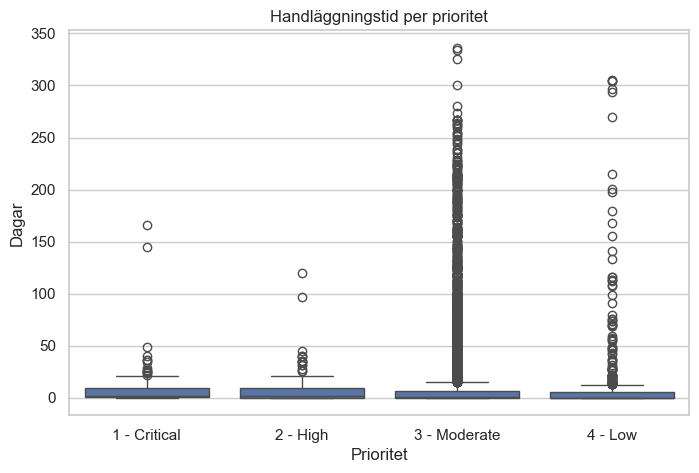

In [22]:
# Fördelning av handläggningstid per prioritet
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_grouped,
    x="priority",
    y="handling_time_days",
    order=[
        "1 - Critical",
        "2 - High",
        "3 - Moderate",
        "4 - Low",
    ],
)

plt.title("Handläggningstid per prioritet")
plt.xlabel("Prioritet")
plt.ylabel("Dagar")
plt.savefig("../images/eda_per_prioritet.png", dpi=150, bbox_inches="tight")
plt.show()

Skillnaderna i handläggningstid mellan prioritetsnivåerna är relativt små jämfört med variationen inom grupperna.   
Diagrammet visar också flera ärenden med mycket långa handläggningstider, särskilt inom nivåerna Moderate och Low.   
Detta tyder på att prioritet ensam inte kan förklara den stora variationen i handläggningstid.

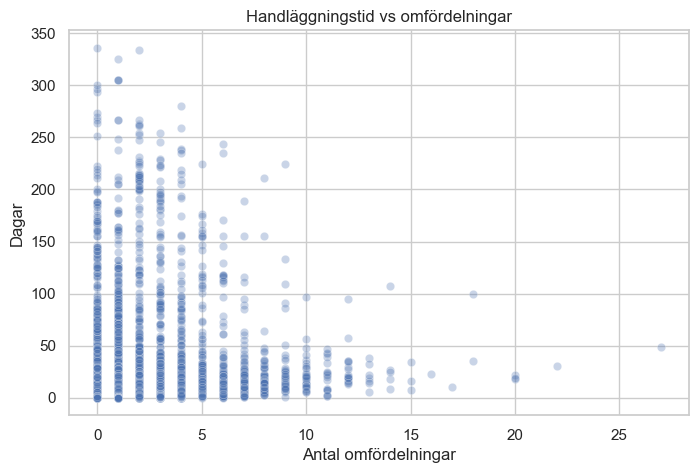

In [23]:
# Handläggningstid mot antal omfördelningar
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_grouped,
    x="reassignment_count",
    y="handling_time_days",
    alpha=0.3,
)

plt.title("Handläggningstid vs omfördelningar")
plt.xlabel("Antal omfördelningar")
plt.ylabel("Dagar")
plt.savefig("../images/eda_vs_omfordelningar.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
# Korrelation mellan antal omfördelningar och handläggningstid
print(df_grouped[["reassignment_count", "handling_time_days"]].corr())

                    reassignment_count  handling_time_days
reassignment_count            1.000000            0.208123
handling_time_days            0.208123            1.000000


Ärenden med fler omfördelningar tenderar generellt att ha längre handläggningstid, men sambandet är svagt (korrelation ≈ 0,21).   
Samtidigt är variationen stor, vilket tyder på att även andra faktorer kan vara kopplade till handläggningstiden.

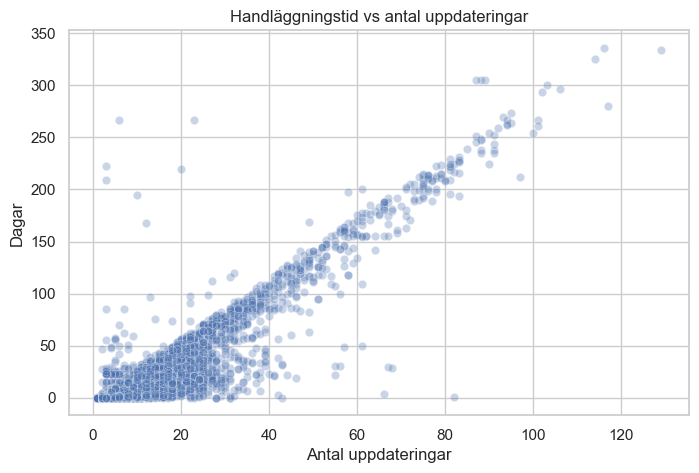

In [25]:
# Handläggningstid mot antal uppdateringar
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_grouped,
    x="sys_mod_count",
    y="handling_time_days",
    alpha=0.3,
)

plt.title("Handläggningstid vs antal uppdateringar")
plt.xlabel("Antal uppdateringar")
plt.ylabel("Dagar")
plt.savefig("../images/eda_vs_uppdateringar.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
# Korrelation mellan antal uppdateringar och handläggningstid
print(df_grouped[["sys_mod_count", "handling_time_days"]].corr())

                    sys_mod_count  handling_time_days
sys_mod_count            1.000000            0.899515
handling_time_days       0.899515            1.000000


Det finns ett mycket starkt positivt samband mellan antalet uppdateringar och handläggningstiden (korrelation ≈ 0,90).  
Antalet uppdateringar ackumuleras under ärendets gång och är därför nära kopplat till processens längd.  
Variabeln exkluderas från modelleringen för att begränsa användningen av information som ligger nära målvariabeln.

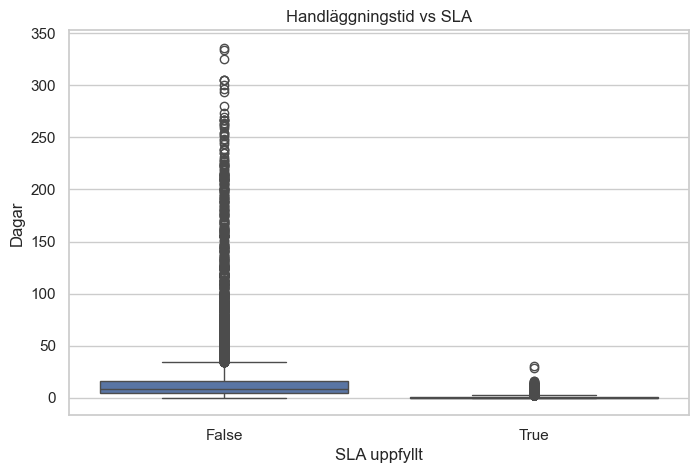

In [27]:
# Handläggningstid beroende på om SLA uppfylldes
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_grouped,
    x="made_sla",
    y="handling_time_days",
)

plt.title("Handläggningstid vs SLA")
plt.xlabel("SLA uppfyllt")
plt.ylabel("Dagar")
plt.savefig("../images/eda_vs_sla.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# Medelvärde, median och antal ärenden per SLA-utfall
print(
    df_grouped.groupby("made_sla")["handling_time_days"]
    .agg(["mean", "median", "count"])
)

               mean    median  count
made_sla                            
False     18.262966  8.391667   8930
True       0.716942  0.045139  14432


Ärenden som inte uppfyller SLA har betydligt längre handläggningstid (genomsnitt 18,26 dagar) än ärenden som uppfyller SLA (genomsnitt 0,72 dagar).  
SLA-utfallet fastställs utifrån ärendets hantering och är därmed nära kopplat till handläggningstiden.   
Variabeln exkluderas från modelleringen för att undvika att använda information som direkt återspeglar utfallet av handläggningsprocessen.

---

## Preprocessering


In [29]:
# Välj variabler för modellering
# Exkluderade variabler:
# - sys_mod_count: nära kopplad till handläggningstiden
# - high_activity_case: beräknad från sys_mod_count
# - made_sla: nära kopplad till utfallet av handläggningen
# - impact, urgency: överlappar med priority

df_model = df_grouped[
    [
        "priority",
        "reassignment_count",
        "reopened_case",
        "assignment_group",
        "category",
        "subcategory",
        "contact_type",
        "handling_time_days",  # målvariabel
    ]
]

# Skapa X och y
X = df_model.drop(columns="handling_time_days")
y = df_model["handling_time_days"]

# Dela upp i tränings- och testdata (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

Relevanta variabler har valts ut för modelleringen och datan har delats upp i tränings- och testdata (80/20).   

In [30]:
# Kontrollera vilka variabler som valts ut för modelleringen
print(f"Antal features: {X.shape[1]}")
print(f"Features: {list(X.columns)}")

Antal features: 7
Features: ['priority', 'reassignment_count', 'reopened_case', 'assignment_group', 'category', 'subcategory', 'contact_type']


In [31]:
# Gruppera kategorier till de 10 vanligaste + "Other"
class TopCategories(BaseEstimator, TransformerMixin):
    def __init__(self, columns, top_n=10):
        self.columns = columns
        self.top_n = top_n

    def fit(self, X, y=None):
        self.top_values_ = {}
        for col in self.columns:
            self.top_values_[col] = (
                X[col].value_counts().nlargest(self.top_n).index.tolist()
            )
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.columns:
            X[col] = X[col].where(
                X[col].isin(self.top_values_[col]), "Other"
            )
        return X

Förbehandlingen har definierats så att kategorier med många unika värden grupperas till de tio vanligaste, medan övriga samlas under "Other".

In [32]:
# Kategoriska och numeriska variabler
categorical_cols = [
    "priority",
    "assignment_group",
    "category",
    "subcategory",
    "contact_type",
]

numeric_cols = [
    "reassignment_count",
    "reopened_case",
]

grouped_cols = [
    "assignment_group",
    "category",
    "subcategory",
]

# Omvandla kategoriska variabler till numeriskt format
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols),
    ]
)

De kategoriska och numeriska variablerna har identifierats.   
Förbehandlingen har definierats så att kategoriska variabler kan omvandlas till numeriskt format genom one-hot encoding.

---

## Modellering och jämförelse


In [33]:
# Definiera modeller
models = [
    ("Linear Regression", LinearRegression()),
    (
        "Random Forest",
        RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            random_state=42,
        ),
    ),
    (
        "Gradient Boosting",
        GradientBoostingRegressor(random_state=42),
    ),
]

# Naiv baseline: förutsäger alltid medianen
dummy = DummyRegressor(strategy="median")

# Femfaldig korsvalidering på träningsdata
cv_candidates = [("Naiv baseline (median)", dummy)] + models

cv_results = []

for name, model in cv_candidates:
    model_pipeline = Pipeline(
        steps=[
            ("group_categories", TopCategories(grouped_cols, top_n=10)),
            ("preprocessor", preprocessor),
            ("model", model),
        ]
    )

    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
    )

    cv_results.append(
        {
            "Modell": name,
            "MAE": -scores["test_mae"].mean(),
            "MAE (std)": scores["test_mae"].std(),
            "R²": scores["test_r2"].mean(),
        }
    )

Fyra modeller har jämförts genom femfaldig korsvalidering:   
en naiv baslinje som förutsäger medianvärdet, Linear Regression, Random Forest och Gradient Boosting.   
Modellernas prediktionsförmåga och stabilitet har utvärderats med MAE, R² och variationen i MAE mellan korsvalideringens delar.

In [34]:
# Sammanställ resultat, sorterade efter MAE
results = (
    pd.DataFrame(cv_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

results

,Modell,MAE,MAE (std),R²
0,Naiv baseline (median),7.294801,0.357154,-0.087163
1,Random Forest,7.876631,0.234314,0.169487
2,Gradient Boosting,7.899694,0.208779,0.163720
3,Linear Regression,8.543846,0.184644,0.130073


Den naiva baslinjen uppvisar lägst MAE (7,29 dagar), medan de tränade modellerna har högre prediktionsfel (7,88–8,54 dagar).   
Samtidigt uppvisar de tränade modellerna positiva R²-värden (0,13–0,17), vilket visar att de kan förklara en begränsad del av variationen i handläggningstid.   
Random Forest har högst R² (0,17), men presterar inte bättre än baslinjen utifrån MAE.

In [35]:
# Jämför faktiska och predikterade värden med korsvalidering på träningsdata
for name, model in models:
    model_pipeline = Pipeline(
        steps=[
            ("group_categories", TopCategories(grouped_cols, top_n=10)),
            ("preprocessor", preprocessor),
            ("model", model),
        ]
    )

    y_pred = cross_val_predict(
        model_pipeline,
        X_train,
        y_train,
        cv=5
    )

    pred_mean = y_pred.mean()
    pred_median = np.median(y_pred)

    print(f"{name}:")
    print(
        f"Faktiskt medel: {y_train.mean():.2f}, "
        f"Predikterat medel: {pred_mean:.2f}"
    )
    print(
        f"Faktisk median: {y_train.median():.2f}, "
        f"Predikterad median: {pred_median:.2f}"
    )
    print()

Linear Regression:
Faktiskt medel: 7.41, Predikterat medel: 7.40
Faktisk median: 0.92, Predikterad median: 5.91

Random Forest:
Faktiskt medel: 7.41, Predikterat medel: 7.39
Faktisk median: 0.92, Predikterad median: 4.15

Gradient Boosting:
Faktiskt medel: 7.41, Predikterat medel: 7.41
Faktisk median: 0.92, Predikterad median: 4.69



Modellernas predikterade medelvärden ligger nära det faktiska medelvärdet på 7,41 dagar.   
Däremot är de predikterade medianerna (4,15–5,91 dagar) betydligt högre än den faktiska medianen på 0,92 dagar.   
Detta visar att modellerna tenderar att överskatta handläggningstiden för ett typiskt ärende.

### Log-transformering

In [36]:
# Log-transformera målvariabeln för att hantera snedfördelad handläggningstid
def with_log_target(model):
    """Träna på log1p(y) och räkna tillbaka prediktionerna till dagar med expm1."""
    return TransformedTargetRegressor(
        regressor=model,
        func=np.log1p,
        inverse_func=np.expm1,
    )


# Femfaldig korsvalidering med log-transformerad målvariabel
# MAE beräknas i dagar efter återtransformering
cv_results_log = []

for name, model in [("Naiv baseline (median, log)", dummy)] + models:

    # Förbehandling och modellträning inom korsvalideringen
    model_pipeline = Pipeline(
        steps=[
            ("group_categories", TopCategories(grouped_cols, top_n=10)),
            ("preprocessor", preprocessor),
            ("model", model),
        ]
    )

    scores = cross_validate(
        with_log_target(model_pipeline),
        X_train,
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
    )

    # Samla resultaten för varje modell
    cv_results_log.append(
        {
            "Modell": name,
            "MAE": -scores["test_mae"].mean(),
            "MAE (std)": scores["test_mae"].std(),
            "R²": scores["test_r2"].mean(),
        }
    )

För att hantera den snedfördelade handläggningstiden har målvariabeln log-transformerats.   
Prediktionerna har räknats tillbaka till dagar och modellerna har utvärderats genom femfaldig korsvalidering på träningsdata.

In [37]:
# Sammanställ resultaten och sortera efter MAE
results_log = (
    pd.DataFrame(cv_results_log)
    .sort_values("MAE")
    .reset_index(drop=True)
)

results_log

,Modell,MAE,MAE (std),R²
0,Gradient Boosting,6.463084,0.306500,0.046854
1,Random Forest,6.525734,0.304392,0.035997
2,"Naiv baseline (median, log)",7.294801,0.357154,-0.087163
3,Linear Regression,8.166092,1.537417,-27.135883


Log-transformeringen har förbättrat MAE för Gradient Boosting och Random Forest jämfört med modellerna utan log-transformering.   
Gradient Boosting uppvisar lägst MAE (6,46 dagar), följt av Random Forest (6,53 dagar).   
Båda presterar bättre än den naiva baslinjen (7,29 dagar), men deras låga R²-värden visar att endast en begränsad del av variationen i handläggningstid förklaras.

In [38]:
# Kontrollera Linear Regressions prediktioner i dagar (korsvaliderade, träningsdata)
lr_pipeline = Pipeline(
    steps=[
        ("group_categories", TopCategories(grouped_cols, top_n=10)),
        ("preprocessor", preprocessor),
        ("model", dict(models)["Linear Regression"]),
    ]
)

lr_log = with_log_target(lr_pipeline)

y_pred_lr_days = cross_val_predict(
    lr_log,
    X_train,
    y_train,
    cv=5
)

print("Min predikterat värde (dagar):", y_pred_lr_days.min())
print("Max predikterat värde (dagar):", y_pred_lr_days.max())

Min predikterat värde (dagar): -0.22677462892632994
Max predikterat värde (dagar): 15036.089626822086


Linear Regression predikterar som mest cirka 15 036 dagar, långt över de faktiska handläggningstiderna, och som minst −0,23 dagar.  
De extrema prediktionerna ger stora fel och förklarar det mycket låga R²-värdet (−27,14).

### Hyperparameteroptimering

In [39]:
# Hyperparameteroptimering med RandomizedSearchCV

# Hyperparametrar att testa för Random Forest
rf_param_dist = {
    "regressor__model__n_estimators": [100, 200, 300, 500],
    "regressor__model__max_depth": [3, 5, 7, 10, None],
    "regressor__model__min_samples_leaf": [1, 2, 5, 10],
}

# Hyperparametrar att testa för Gradient Boosting
gb_param_dist = {
    "regressor__model__n_estimators": [100, 200, 300],
    "regressor__model__max_depth": [2, 3, 4, 5],
    "regressor__model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "regressor__model__min_samples_leaf": [1, 5, 10],
}

In [40]:
# Skapa pipeline med förbehandling och Random Forest
rf_pipeline = Pipeline(
    steps=[
        ("group_categories", TopCategories(grouped_cols, top_n=10)),
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42)),
    ]
)

# Optimera med log-transformerad målvariabel
rf_search = RandomizedSearchCV(
    estimator=with_log_target(rf_pipeline),
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
)

rf_search.fit(X_train, y_train)

print("Bästa parametrar för Random Forest:")
print(rf_search.best_params_)
print(f"Bästa MAE vid korsvalidering: {-rf_search.best_score_:.2f} dagar")

Bästa parametrar för Random Forest:
{'regressor__model__n_estimators': 200, 'regressor__model__min_samples_leaf': 1, 'regressor__model__max_depth': 10}
Bästa MAE vid korsvalidering: 6.41 dagar


In [41]:
# Skapa pipeline med förbehandling och Gradient Boosting
gb_pipeline = Pipeline(
    steps=[
        ("group_categories", TopCategories(grouped_cols, top_n=10)),
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(random_state=42)),
    ]
)

# Optimera med log-transformerad målvariabel
gb_search = RandomizedSearchCV(
    estimator=with_log_target(gb_pipeline),
    param_distributions=gb_param_dist,
    n_iter=15,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
)

gb_search.fit(X_train, y_train)

print("Bästa parametrar för Gradient Boosting:")
print(gb_search.best_params_)
print(f"Bästa MAE vid korsvalidering: {-gb_search.best_score_:.2f} dagar")

Bästa parametrar för Gradient Boosting:
{'regressor__model__n_estimators': 300, 'regressor__model__min_samples_leaf': 1, 'regressor__model__max_depth': 5, 'regressor__model__learning_rate': 0.05}
Bästa MAE vid korsvalidering: 6.41 dagar


Random Forest och Gradient Boosting har hyperparameteroptimerats med RandomizedSearchCV genom femfaldig korsvalidering på träningsdata.   
För båda modellerna har 15 hyperparameterkombinationer testats. Optimeringen gav ett MAE på cirka 6,41 dagar för båda modellerna, vilket är en förbättring jämfört med resultaten före optimeringen.

### Modellval och slutlig utvärdering


In [42]:
# Jämför modeller utifrån korsvalidering på träningsdata (MAE i dagar)

# Resultat från tidigare korsvalidering med log-transformerad målvariabel
cv_comparison = results_log[["Modell", "MAE"]].copy()
cv_comparison = cv_comparison.rename(columns={"MAE": "CV-MAE (dagar)"})

# Lägg till resultaten från hyperparameteroptimeringen
optimized_results = pd.DataFrame(
    [
        {
            "Modell": "Random Forest (optimerad)",
            "CV-MAE (dagar)": -rf_search.best_score_,
        },
        {
            "Modell": "Gradient Boosting (optimerad)",
            "CV-MAE (dagar)": -gb_search.best_score_,
        },
    ]
)

# Sammanställ och sortera efter lägst MAE
cv_comparison = pd.concat(
    [cv_comparison, optimized_results],
    ignore_index=True
)

cv_comparison = (
    cv_comparison
    .sort_values("CV-MAE (dagar)")
    .reset_index(drop=True)
)

cv_comparison

,Modell,CV-MAE (dagar)
0,Gradient Boosting (optimerad),6.409706
1,Random Forest (optimerad),6.410779
2,Gradient Boosting,6.463084
3,Random Forest,6.525734
4,"Naiv baseline (median, log)",7.294801
5,Linear Regression,8.166092


De optimerade modellerna uppvisar lägst korsvaliderat MAE.   
Gradient Boosting har det lägsta värdet (6,410 dagar), tätt följt av Random Forest (6,411 dagar).   
Skillnaden mellan modellerna är mycket liten. Båda presterar bättre än den naiva baslinjen (7,29 dagar).

In [43]:
# Välj modellen med lägst CV-MAE på träningsdata
best_model_name = cv_comparison.iloc[0]["Modell"]

# Koppla modellnamnen till respektive modell
model_lookup = {
    "Naiv baseline (median, log)": with_log_target(
        Pipeline(
            steps=[
                ("group_categories", TopCategories(grouped_cols, top_n=10)),
                ("preprocessor", preprocessor),
                ("model", DummyRegressor(strategy="median")),
            ]
        )
    ),
    "Linear Regression": with_log_target(
        Pipeline(
            steps=[
                ("group_categories", TopCategories(grouped_cols, top_n=10)),
                ("preprocessor", preprocessor),
                ("model", LinearRegression()),
            ]
        )
    ),
    "Random Forest": with_log_target(
        Pipeline(
            steps=[
                ("group_categories", TopCategories(grouped_cols, top_n=10)),
                ("preprocessor", preprocessor),
                ("model", RandomForestRegressor(
                    n_estimators=300,
                    max_depth=5,
                    random_state=42
                )),
            ]
        )
    ),
    "Gradient Boosting": with_log_target(
        Pipeline(
            steps=[
                ("group_categories", TopCategories(grouped_cols, top_n=10)),
                ("preprocessor", preprocessor),
                ("model", GradientBoostingRegressor(random_state=42)),
            ]
        )
    ),
    "Random Forest (optimerad)": rf_search.best_estimator_,
    "Gradient Boosting (optimerad)": gb_search.best_estimator_,
}

# Hämta den modell som har lägst CV-MAE
best_model = model_lookup[best_model_name]

# Träna modellen om den inte redan har tränats
if best_model_name not in [
    "Random Forest (optimerad)",
    "Gradient Boosting (optimerad)",
]:
    best_model.fit(X_train, y_train)

print(f"Vald modell: {best_model_name}")

Vald modell: Gradient Boosting (optimerad)


In [44]:
# Utvärdera den valda modellen på testdata
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred

test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"MAE på testdata: {test_mae:.2f} dagar, R²: {test_r2:.2f}")

MAE på testdata: 6.54 dagar, R²: 0.06


Den optimerade Gradient Boosting-modellen har utvärderats på testdata och uppvisar ett MAE på 6,54 dagar och ett R²-värde på 0,06.   
Resultatet visar att modellens förmåga att förklara variationen i handläggningstid är begränsad.

---

## Modelltolkning och variabelbetydelse

In [45]:
# Hämta den tränade valda modellen
trained_pipeline = best_model.regressor_
trained_model = trained_pipeline.named_steps["model"]

# Hämta variabelnamn efter förbehandling
feature_names = (
    trained_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Sammanställ variabelbetydelse
feature_importance = pd.DataFrame({
    "Features": feature_names,
    "Importance": trained_model.feature_importances_
})

# Sortera med viktigaste variabeln först
feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

feature_importance.head(10)

,Features,Importance
41,num__reassignment_count,0.491818
12,cat__assignment_group_Group 70,0.133931
14,cat__assignment_group_Other,0.126633
25,cat__category_Other,0.031408
11,cat__assignment_group_Group 64,0.024157
7,cat__assignment_group_Group 25,0.023752
26,cat__subcategory_Other,0.022263
10,cat__assignment_group_Group 39,0.015267
42,num__reopened_case,0.012237
1,cat__priority_2 - High,0.011443


Antal omfördelningar (reassignment_count) är den överlägset viktigaste variabeln med en betydelse på cirka 0,49, följt av tilldelningsgrupperna Group 70 (0,13) och Other (0,13).   
De flesta övriga variabler bidrar var för sig mycket lite.

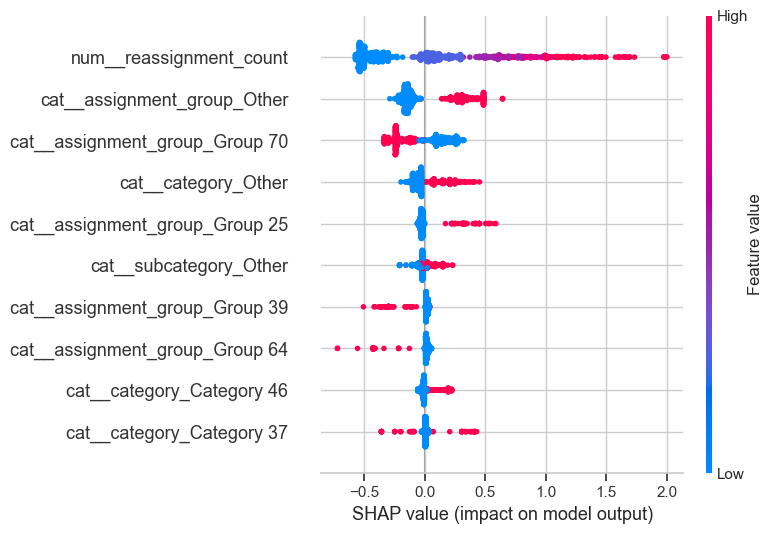

In [46]:
# SHAP-analys för den valda modellen
# Urval av 1000 ärenden från träningsdata
X_shap = X_train.sample(1000, random_state=42)

# Använd samma förbehandling som vid modellträningen
X_shap_transformed = trained_pipeline[:-1].transform(X_shap)
X_shap_transformed = X_shap_transformed.toarray().astype(float)

# Skapa SHAP-förklarare för den tränade modellen
explainer = shap.TreeExplainer(trained_model)
shap_values = explainer.shap_values(X_shap_transformed)

# Visa de 10 viktigaste variablerna och spara bilden
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=10,
    show=False
)

plt.savefig("../images/shap.png", dpi=150, bbox_inches="tight")
plt.show()

SHAP-analysen visar att antal omfördelningar (reassignment_count) har störst påverkan på modellens prediktioner.   
Ett högre antal omfördelningar är generellt förknippat med längre predikterad handläggningstid, medan färre omfördelningar främst bidrar till lägre prediktioner.

Även tilldelningsgrupperna Other och Group 70 har betydelse, men deras påverkan skiljer sig åt.   
Tillhörighet till Other är främst förknippad med högre predikterad handläggningstid, medan Group 70 generellt bidrar till lägre prediktioner.   
Övriga variabler har mindre påverkan på modellens prediktioner.

SHAP-värdena redovisas på modellens log-transformerade skala och ska därför inte tolkas som direkta förändringar i antal dagar.

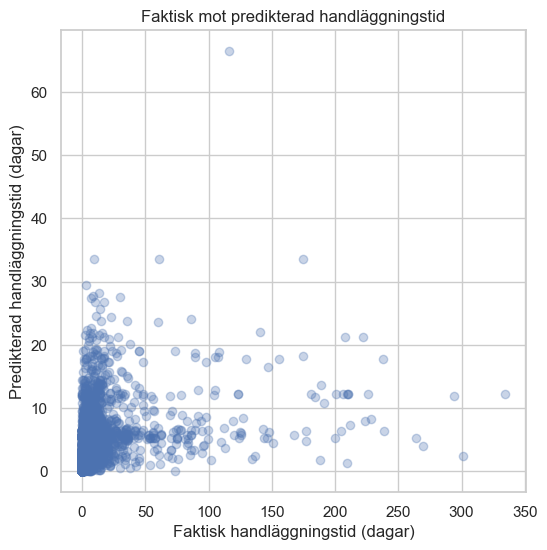

In [47]:
# Jämför faktisk och predikterad handläggningstid på testdata
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Faktisk handläggningstid (dagar)")
plt.ylabel("Predikterad handläggningstid (dagar)")
plt.title("Faktisk mot predikterad handläggningstid")
plt.savefig("../images/faktisk_vs_predikterad.png", dpi=150, bbox_inches="tight")
plt.show()

Sambandet mellan faktisk och predikterad handläggningstid är svagt, vilket överensstämmer med modellens R²-värde på 0,06.  
Modellen underskattar genomgående de allra längsta ärendena. De högsta predikterade tiderna är drygt 65 dagar, medan de faktiska tiderna överstiger 300 dagar.  
Detta visar att modellen, trots log-transformeringen, fortfarande har svårt att förutsäga de mest extrema handläggningstiderna.

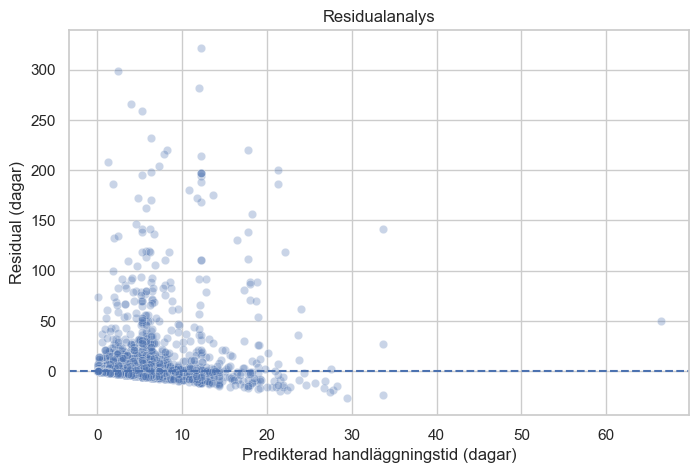

In [48]:
# Residualanalys: faktiskt minus predikterat mot predikterad handläggningstid
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.3,
)
plt.axhline(0, linestyle="--")
plt.xlabel("Predikterad handläggningstid (dagar)")
plt.ylabel("Residual (dagar)")
plt.title("Residualanalys")
plt.savefig("../images/residualanalys.png", dpi=150, bbox_inches="tight")
plt.show()

Residualanalysen visar att modellens fel inte är jämnt fördelade kring noll.   
Flera ärenden har stora positiva residualer, vilket innebär att den faktiska handläggningstiden är betydligt längre än den predikterade.   
Negativa residualer förekommer också och visar att modellen överskattar handläggningstiden för vissa ärenden.

Den ojämna spridningen visar att modellen har svårt att förutsäga handläggningstiden för vissa ärenden, särskilt de med mycket långa faktiska handläggningstider.

---

## Executive Summary

Projektet analyserar handläggningstid i ett ärendehanteringssystem med syfte att identifiera faktorer kopplade till processens effektivitet samt undersöka om handläggningstid kan predikteras med hjälp av maskininlärning.

EDA visade att handläggningstiden är kraftigt snedfördelad, där ett fåtal långdragna ärenden driver upp genomsnittet jämfört med medianen.   
Antal omfördelningar visade ett svagt samband med handläggningstiden, medan prioritet hade förhållandevis liten påverkan.

Variablerna `sys_mod_count`, `high_activity_case` och `made_sla` identifierades som target leakage, eftersom de speglar processens utfall och inte är kända i förväg och exkluderades därför från modelleringen.

Fyra modeller testades: en naiv baseline, Linear Regression, Random Forest och Gradient Boosting. Modellerna jämfördes med korsvalidering på träningsdata och testdata användes endast för den slutliga utvärderingen.  
Utan log-transformering hade den naiva baslinjen lägst MAE. Efter log-transformering förbättrades resultaten för Random Forest och Gradient Boosting.

Efter hyperparameteroptimering valdes Gradient Boosting (optimerad).   
Modellen fick MAE 6,54 dagar och R² 0,06 på testdata, vilket innebär att den endast förklarar en liten del av variationen i handläggningstid.

SHAP-analysen visade att antal omfördelningar hade störst betydelse för modellens prediktioner.   
Även tilldelningsgrupperna hade betydelse, medan prioritet inte fanns bland de tio viktigaste variablerna.  
Modellen underskattade systematiskt de mest långdragna ärendena, vilket tyder på att mycket av variationen i handläggningstid kan bero på faktorer som inte finns i datasetet.

Antal omfördelningar och tilldelad grupp avser värdena när ärendet avslutades, så analysen gäller historiska, avslutade ärenden och inte prediktion vid en bestämd tidpunkt.  
Resultaten visar att flera processrelaterade faktorer har samband med handläggningstid, men att modellens förmåga att förklara variationen är begränsad.